# Anson 1: Hail-Storm Production and Cost-of-Outage Analysis

On May 2, 2024, a hailstorm crossed the Anson 1 solar plant near Abilene, Texas.
This notebook sizes the financial impact of that storm end to end, using
the **[EnergyStream API](https://energystream.io/api-reference)**. If you sign up for a professional EnergyStream account, you can run this and get the same charts and numbers for Anson. Data for this site specifically has been made public **[here](https://energystream.io/utility-data/states/texas/anson-solar-center-llc-11724)**.

**Requires a Professional or Enterprise API key.** See the [API docs](https://energystream.io/docs/api) and the
[interactive reference](https://energystream.io/api-reference) for the full list of endpoints that are public or professional/enterprise.

## Setup

This notebook reads your key via `os.environ.get("ENERGYSTREAM_API_KEY")`, so
it has to already be in the environment of the process that launches Jupyter -
setting it only in the terminal you happen to be typing in, or only after
Jupyter is already running, will not reach the kernel.

**macOS/Linux** - `export` works, but only lasts for that terminal session.
For something that survives new terminals/reboots, add it to your shell
profile (`~/.bashrc`, `~/.zshrc`, etc.):

```bash
export ENERGYSTREAM_API_KEY=es_live_...
```

**Windows** - `$env:ENERGYSTREAM_API_KEY = "..."` in PowerShell is also
session-only. Use `setx` once to persist it to your user profile:

```powershell
setx ENERGYSTREAM_API_KEY "es_live_..."
```

Either way, **open a new terminal (or reboot) and start Jupyter from there** -
a Jupyter server that was already running before you set the variable
will not pick it up; restarting the kernel alone doesn't help, since the
variable lives at the process level, not the kernel level. The server
itself has to be a fresh process started after the variable exists.

In [37]:
%matplotlib inline
import os
import sys
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import pandas as pd
import requests

BASE_URL = os.environ.get("ENERGYSTREAM_API_BASE_URL", "https://energystream.io/api/v1")
PLANT_ID = "11724"  # Anson Solar Center, Jones County, TX

API_KEY = os.environ.get("ENERGYSTREAM_API_KEY")
if not API_KEY:
    sys.exit(
        "Set ENERGYSTREAM_API_KEY first. Generate a key from your "
        "EnergyStream profile page (Professional or Enterprise plan)."
    )

SESSION = requests.Session()
SESSION.headers.update({"Authorization": f"Bearer {API_KEY}"})

## Helpers

Two small wrappers used by every step below:

- `call()` — a single GET, with a plain-English error instead of a raw
  HTTP exception when a 403 (plan doesn't include this endpoint) or 429
  (rate limited) comes back.
- `fetch_all_rows()` — walks a time-series endpoint's `start`/`end`
  window forward automatically. Professional plans cap how much history one
  request can cover (the response's `window.max_days`); Enterprise is
  uncapped and this returns everything in a single call.

In [38]:
def call(path, params=None):
    """GET one /api/v1 endpoint and return its `data` object. Raises with a
    plain-English explanation on anything other than 200 - a 403 here almost
    always means the key's plan doesn't include this endpoint, not a bug in
    this script."""
    resp = SESSION.get(f"{BASE_URL}{path}", params=params)
    if resp.status_code == 403:
        raise RuntimeError(
            f"{path} -> 403. This endpoint needs a Professional or "
            f"Enterprise plan; a Free-plan key cannot reach it. "
            f"Response: {resp.text}"
        )
    if resp.status_code == 429:
        raise RuntimeError(f"{path} -> 429 rate limited: {resp.text}")
    resp.raise_for_status()
    return resp.json()["data"]


def fetch_all_rows(path, params, start, end):
    """GET every row of a windowed/time-series endpoint across `start` to
    `end`, inclusive, handling the per-request-plan cap on history length
    (the response's `window.max_days`) by walking forward in that many
    days per call. A null `max_days` (Enterprise) means the whole range
    came back in one call."""
    rows = []
    cursor = start
    while cursor <= end:
        data = call(path, {**params, "start": iso(cursor), "end": iso(end)})
        rows.extend(data["rows"])
        max_days = (data.get("window") or {}).get("max_days")
        if not max_days:
            break
        cursor = cursor + timedelta(days=max_days)
    return rows


def iso(dt):
    return dt.strftime("%Y-%m-%dT%H:%M:%SZ")

# Roll up 15-minute data to local (Central) operating days, so we can build daily performance plots
def to_daily_by_unit(df, value_col="ac_energy_mwh"):
    local_date = (
        df["timestamp_utc"].dt.tz_convert("America/Chicago").dt.tz_localize(None).dt.normalize()
    )
    return df.assign(date=local_date).groupby(["date", "unit_code"])[value_col].sum().unstack("unit_code")

## Step 1: Plant Metadata

Pull the plant metadata via the following endpoints: 

- `GET /facilities/{plant_id}/iso-plant` — Pulls metadata for the two ISO units associated with Anson.
- `GET /facilities/{plant_id}/iso-node-relationships` — pulls the associated node for the Anson site, which allows us to link to node settlement prices.

In [39]:
print("Fetching ISO unit(s) for plant", PLANT_ID, "...")
iso_plant_rows = call(f"/facilities/{PLANT_ID}/iso-plant")["rows"]
iso_plants = pd.DataFrame(iso_plant_rows)
print(iso_plants[["iso_id", "unit_code", "iso", "installed_capacity_mw"]])

# node_id values for financials/settlement-prices are available via
# /facilities/{plant_id}/iso-node-relationships.
print("\nFetching ISO node relationship(s) ...")
node_rows = call(f"/facilities/{PLANT_ID}/iso-node-relationships")["rows"]
node_relations = pd.DataFrame(node_rows)
print(node_relations[["iso_id", "resource_node"]])

unit_codes = iso_plants["unit_code"].dropna().unique().tolist()
node_id = node_relations["iso_id"].dropna().unique()[0]
# Commissioning date, so the full-history pulls below don't start earlier
# than the plant has ever had data.
generators = pd.DataFrame(call(f"/facilities/{PLANT_ID}/generators")["rows"])

Fetching ISO unit(s) for plant 11724 ...
   iso_id     unit_code    iso  installed_capacity_mw
0    2243  ANSON1_UNIT2  ERCOT                  100.8
1    2242  ANSON1_UNIT1  ERCOT                  100.8

Fetching ISO node relationship(s) ...
   iso_id resource_node
0    2242    ANSON1_ALL


## Step 2: Outage Data

Pull the plant outage data via the following endpoint: 

- `GET /facilities/{plant_id}/outages` — Pulls outage data for the associated Anson plant

In [40]:
# Pull down the hail outage data and get the associated start and end dates for outages attributed to cold weather/ice
print("\nFetching outage events ...")
outage_rows = call(
    f"/facilities/{PLANT_ID}/outages",
    {"start": iso(pd.to_datetime("2024-01-01").tz_localize("UTC"))},
)["rows"]
outages_df = pd.DataFrame(outage_rows)
outages_df["start_timestamp_utc"] = pd.to_datetime(outages_df["start_timestamp_utc"], utc=True)
outages_df["end_timestamp_utc"] = pd.to_datetime(outages_df["end_timestamp_utc"], utc=True)
outages_df = outages_df[outages_df["reason"] == "COLD WEATHER RELATED"]

print(outages_df[['iso_id','start_timestamp_utc', 'end_timestamp_utc', 'outage_type', 'reason']])

hail_damage_date = pd.Timestamp("2024-05-02")
outage_end = pd.Timestamp("2024-12-31")
current_date = pd.Timestamp.now(tz="UTC")


Fetching outage events ...
    iso_id       start_timestamp_utc         end_timestamp_utc  \
2     2242 2024-05-02 12:00:00+00:00 2024-06-01 04:59:00+00:00   
3     2243 2024-05-02 12:00:00+00:00 2024-06-01 04:59:00+00:00   
18    2242 2024-08-01 12:05:00+00:00 2024-08-25 15:30:00+00:00   
19    2243 2024-08-01 12:05:00+00:00 2024-08-31 04:59:00+00:00   
20    2242 2024-08-25 15:30:00+00:00 2024-08-31 04:59:00+00:00   
22    2243 2024-09-01 05:01:00+00:00 2024-10-01 04:59:00+00:00   
23    2242 2024-09-01 05:01:00+00:00 2024-10-01 04:59:00+00:00   
24    2242 2024-10-01 05:01:00+00:00 2024-11-19 19:12:00+00:00   
25    2243 2024-10-01 05:01:00+00:00 2024-11-19 19:12:00+00:00   
26    2243 2024-11-19 19:13:00+00:00 2024-12-31 23:12:00+00:00   
27    2242 2024-11-19 19:13:00+00:00 2024-12-31 23:12:00+00:00   

         outage_type                reason  
2             FORCED  COLD WEATHER RELATED  
3             FORCED  COLD WEATHER RELATED  
18            FORCED  COLD WEATHER RELATED  

## Step 3: Full Production History

Actual (ERCOT-reported) production vs. ideal (modeled) generation, for every
15-minute interval since commissioning:

- `GET /facilities/{plant_id}/production/interval` — what the plant
  actually delivered.
- `GET /facilities/{plant_id}/models/iso-generation-estimates` — what the
  PVWatts model says it *should* have produced, weather-adjusted.

Both get rolled up to daily totals per unit (local Central-time calendar
days) below, then plotted.

In [41]:
print(f"\nFetching actual production from {history_start.date()} to {current_date.date()} ...")
actual_rows = fetch_all_rows(
    f"/facilities/{PLANT_ID}/production/interval", {}, history_start, current_date
)
actual = pd.DataFrame(actual_rows)
actual["timestamp_utc"] = pd.to_datetime(actual["timestamp_utc"], utc=True)

print(actual.head())

print("Fetching modeled (PVWatts ISO-calibrated) generation for the same range ...")
ideal_rows = fetch_all_rows(
    f"/facilities/{PLANT_ID}/models/iso-generation-estimates", {}, history_start, current_date
)
ideal = pd.DataFrame(ideal_rows)
ideal["timestamp_utc"] = pd.to_datetime(ideal["timestamp_utc"], utc=True)

print(ideal.head())

actual_daily_by_unit = to_daily_by_unit(actual.merge(iso_plants[["iso_id", "unit_code"]], on="iso_id"))
ideal_daily_by_unit = to_daily_by_unit(ideal)


Fetching actual production from 2021-03-01 to 2026-11-12 ...
   plant_id  iso_id             timestamp_utc  ac_energy_mwh
0     11724    2243 2021-03-01 00:00:00+00:00       7.178657
1     11724    2243 2021-03-01 00:15:00+00:00       3.352511
2     11724    2243 2021-03-01 00:30:00+00:00       0.322530
3     11724    2243 2021-03-01 00:45:00+00:00       0.000000
4     11724    2243 2021-03-01 01:00:00+00:00       0.000000
Fetching modeled (PVWatts ISO-calibrated) generation for the same range ...
   iso_id     unit_code  plant_id    iso             timestamp_utc  \
0    2243  ANSON1_UNIT2     11724  ERCOT 2021-03-01 00:00:00+00:00   
1    2243  ANSON1_UNIT2     11724  ERCOT 2021-03-01 00:15:00+00:00   
2    2243  ANSON1_UNIT2     11724  ERCOT 2021-03-01 00:30:00+00:00   
3    2243  ANSON1_UNIT2     11724  ERCOT 2021-03-01 00:45:00+00:00   
4    2243  ANSON1_UNIT2     11724  ERCOT 2021-03-01 01:00:00+00:00   

   ac_energy_mwh  capacity_is_estimated  
0       4.359396                 

## Step 4: Plot Real vs Ideal Production, including the Hail Outage Period

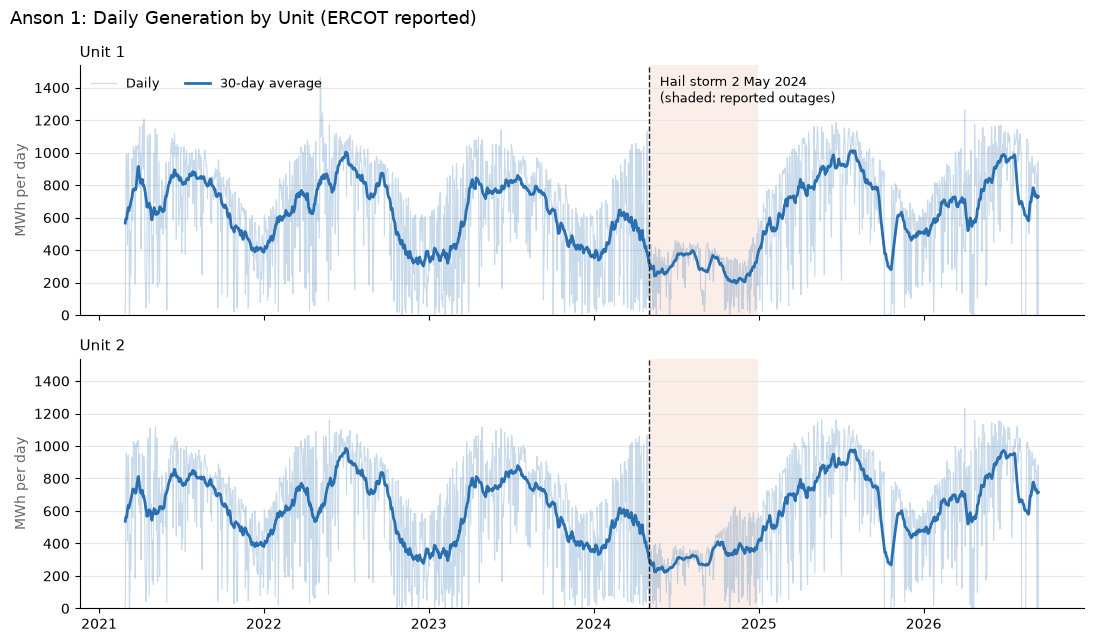

In [42]:
## Plot the two units during the associated outages period
unit_labels = {code: f"Unit {i + 1}" for i, code in enumerate(sorted(actual_daily_by_unit.columns))}
fig, axes = plt.subplots(len(unit_labels), 1, figsize=(11, 6.5), sharex=True, sharey=True)
if len(unit_labels) == 1:
    axes = [axes]
for ax, (code, name) in zip(axes, unit_labels.items()):
    s = actual_daily_by_unit[code]
    ax.plot(s.index, s, color="#2a6fb0", alpha=0.25, lw=0.8, label="Daily")
    ax.plot(s.index, s.rolling(30, center=True, min_periods=15).mean(),
            color="#2a6fb0", lw=2, label="30-day average")
    ax.axvspan(hail_damage_date, outage_end, color="#d9622b", alpha=0.10, lw=0)
    ax.axvline(hail_damage_date, color="#222222", lw=1, ls="--")
    ax.set_ylabel("MWh per day", color="#666666")
    ax.set_title(name, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e6e6e6")
    ax.set_ylim(bottom=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].annotate("Hail storm 2 May 2024\n(shaded: reported outages)",
                  xy=(hail_damage_date, 1), xycoords=("data", "axes fraction"),
                  xytext=(8, -6), textcoords="offset points", va="top", fontsize=9)
axes[0].legend(frameon=False, loc="upper left", ncol=2, fontsize=9)
fig.suptitle("Anson 1: Daily Generation by Unit (ERCOT reported)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig("anson_daily_rollup.png", dpi=200)
plt.show()

## Step 3: Actual vs. Ideal, Both Units Combined

Same two datasets from Step 3, summed across both units, with a rolling
percent-of-ideal to make the storm's severity (and recovery) legible, plus
a year-over-year comparison of the same May–Dec calendar window.

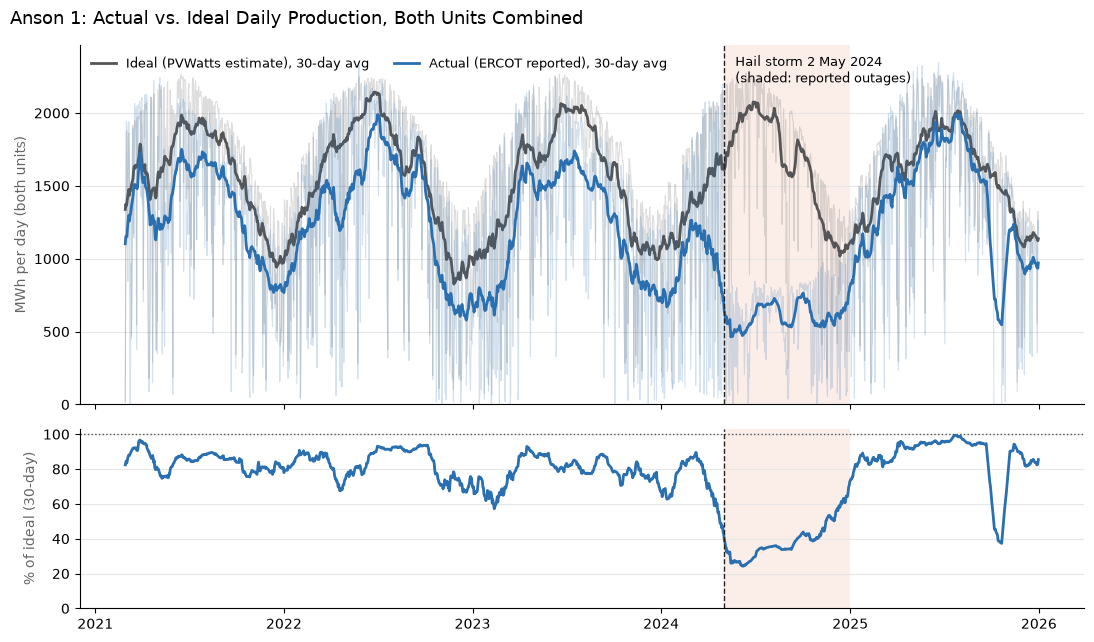

In [43]:
actual_daily = actual_daily_by_unit.sum(axis=1).rename("actual_mwh")
ideal_daily = ideal_daily_by_unit.sum(axis=1).rename("ideal_mwh")
cmp = pd.concat([actual_daily, ideal_daily], axis=1).dropna()
pct_ideal = (
    cmp["actual_mwh"].rolling(30, center=True, min_periods=15).sum()
    / cmp["ideal_mwh"].rolling(30, center=True, min_periods=15).sum() * 100
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for col, color, label in [
    ("ideal_mwh", "#555555", "Ideal (PVWatts estimate)"),
    ("actual_mwh", "#2a6fb0", "Actual (ERCOT reported)"),
]:
    ax1.plot(cmp.index, cmp[col], color=color, alpha=0.2, lw=0.8)
    ax1.plot(cmp.index, cmp[col].rolling(30, center=True, min_periods=15).mean(),
              color=color, lw=2, label=label + ", 30-day avg")
ax2.plot(pct_ideal.index, pct_ideal, color="#2a6fb0", lw=2)
ax2.axhline(100, color="#555555", lw=1, ls=":")
ax1.set_ylabel("MWh per day (both units)", color="#666666")
ax2.set_ylabel("% of ideal (30-day)", color="#666666")
ax1.legend(frameon=False, loc="upper left", ncol=2, fontsize=9)
for ax in (ax1, ax2):
    ax.axvspan(hail_damage_date, outage_end, color="#d9622b", alpha=0.10, lw=0)
    ax.axvline(hail_damage_date, color="#222222", lw=1, ls="--")
    ax.grid(axis="y", color="#e6e6e6")
    ax.set_ylim(bottom=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
ax1.annotate("Hail storm 2 May 2024\n(shaded: reported outages)",
             xy=(hail_damage_date, 1), xycoords=("data", "axes fraction"),
             xytext=(8, -6), textcoords="offset points", va="top", fontsize=9)
fig.suptitle("Anson 1: Actual vs. Ideal Daily Production, Both Units Combined", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig("anson_actual_vs_ideal.png", dpi=200)
plt.show()

In [44]:
outage = cmp.loc[hail_damage_date:outage_end]
print(f"\nHail outage window: actual {outage['actual_mwh'].sum():,.0f} MWh vs. "
      f"ideal {outage['ideal_mwh'].sum():,.0f} MWh "
      f"({outage['actual_mwh'].sum() / outage['ideal_mwh'].sum():.0%} of ideal)")

in_outage = (cmp.index >= hail_damage_date) & (cmp.index <= outage_end)
for label, subset in [
    ("Excluding outage period", cmp[~in_outage]),
    ("Before storm", cmp[cmp.index < hail_damage_date]),
    ("After outage period", cmp[cmp.index > outage_end]),
]:
    print(f"{label}: actual {subset['actual_mwh'].sum():,.0f} MWh vs. "
          f"ideal {subset['ideal_mwh'].sum():,.0f} MWh "
          f"({subset['actual_mwh'].sum() / subset['ideal_mwh'].sum():.1%} of ideal)")

win_start, win_end = (hail_damage_date.month, hail_damage_date.day), (12, 31)
rows = {}
for year in sorted(cmp.index.year.unique()):
    window = cmp.loc[f"{year}-{win_start[0]:02d}-{win_start[1]:02d}":f"{year}-12-31"]
    expected_days = (
        pd.Timestamp(f"{year}-12-31") - pd.Timestamp(f"{year}-{win_start[0]:02d}-{win_start[1]:02d}")
    ).days + 1
    if len(window) < expected_days:
        continue  # partial year
    rows[year] = {"actual_mwh": window["actual_mwh"].sum(), "ideal_mwh": window["ideal_mwh"].sum()}
by_year = pd.DataFrame(rows).T
by_year["pct_of_ideal"] = by_year["actual_mwh"] / by_year["ideal_mwh"] * 100
print("\nMay 2 - Dec 31 production by year:")
print(by_year.round(1))

hail_year = hail_damage_date.year
other = by_year.drop(index=hail_year)
hail = by_year.loc[hail_year]
print(f"\n{hail_year} vs. other years (same May 2 - Dec 31 window, {', '.join(map(str, other.index))}):")
print(f"  Actual MWh: {hail['actual_mwh'] / other['actual_mwh'].mean() - 1:+.1%} vs. the average of other years")
print(f"  % of ideal: {hail['pct_of_ideal']:.1f}% vs. {other['pct_of_ideal'].mean():.1f}% "
      f"({hail['pct_of_ideal'] - other['pct_of_ideal'].mean():+.1f} pts)")


Hail outage window: actual 147,223 MWh vs. ideal 398,919 MWh (37% of ideal)
Excluding outage period: actual 1,956,867 MWh vs. ideal 2,350,141 MWh (83.3% of ideal)
Before storm: actual 1,453,756 MWh vs. ideal 1,775,451 MWh (81.9% of ideal)
After outage period: actual 503,111 MWh vs. ideal 574,690 MWh (87.5% of ideal)

May 2 - Dec 31 production by year:
      actual_mwh  ideal_mwh  pct_of_ideal
2021    325891.5   390327.9          83.5
2022    329083.4   387420.4          84.9
2023    318824.8   393047.3          81.1
2024    147223.0   398918.9          36.9
2025    349425.8   397319.7          87.9

2024 vs. other years (same May 2 - Dec 31 window, 2021, 2022, 2023, 2025):
  Actual MWh: -55.5% vs. the average of other years
  % of ideal: 36.9% vs. 84.4% (-47.5 pts)


## Step 4: Energy and Cost Losses Due to the Outage

Calculate lost energy (ideal minus actual, floored at zero) times the settlement point
price (SPP) for the unit's ISO node, over the specific outage window, using the following endpoint to get settlement prices:

- `GET /facilities/{plant_id}/financials/settlement-prices` — $/MWh for
  the node, to turn lost MWh into a lost dollar figure.

In [49]:
ideal_window = ideal[
        (ideal["timestamp_utc"] >= hail_damage_date.tz_localize("UTC")) & (ideal["timestamp_utc"] <= outage_end.tz_localize("UTC"))
    ].copy()

actual_window = actual_window.rename(columns={"ac_energy_mwh": "actual_energy_mwh"})

combo_prod = pd.merge(
        ideal_window, actual_window[["timestamp_utc", "unit_code", "actual_energy_mwh"]],
        on=["timestamp_utc"], how="left",
    )
combo_prod["lost_energy_mwh"] = (
        combo_prod["ac_energy_mwh"] - combo_prod["actual_energy_mwh"]
    ).clip(lower=0)

print(f"Fetching settlement point prices for node(s) {node_ids} ...")
spp = fetch_all_rows(
            f"/facilities/{PLANT_ID}/financials/settlement-prices",
            {"node_id": node_id}, hail_damage_date, outage_end,
        )

print(spp)
spp["interval_start"] = pd.to_datetime(spp["interval_start"], utc=True)
cost_generation_estimates = pd.merge(
            combo_prod, spp, left_on="timestamp_utc", right_on="interval_start", how="left"
        )
cost_generation_estimates["spp"] = cost_generation_estimates["spp"].ffill()
cost_generation_estimates["lost_energy_cost"] = (
            cost_generation_estimates["lost_energy_mwh"] * cost_generation_estimates["spp"]
        )

print("SUMMED ENERGY COST:")
print(cost_generation_estimates["lost_energy_cost"].sum())

Fetching settlement point prices for node(s) [2242] ...


IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



TypeError: list indices must be integers or slices, not str